The model chosen is the random forest since it's the best model by a clear margin. The random forest beat the decision tree as by 3.4 points with a fold to fold spread under 0.6.

## Final model evaluation

Refits the Random Forest on the *full* training set (not just the 20k-row sample used for tuning) and evaluates it once on the held-out test set — the only time the test set is touched.

In [12]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/features.csv")
X = df.drop(columns=["mod", "snr"])
y = df["mod"]
snrs = df["snr"]

strata = y + "_" + snrs.astype(str)

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snrs,
    test_size=0.2,
    stratify=strata,
    random_state=42,
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42),
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Overall test accuracy: {test_accuracy:.3f}")
print(classification_report(y_test, y_pred))


Overall test accuracy: 0.500
              precision    recall  f1-score   support

        8PSK       0.55      0.34      0.42      4000
      AM-DSB       0.57      0.58      0.57      4000
      AM-SSB       0.25      0.92      0.39      4000
        BPSK       0.78      0.49      0.61      4000
       CPFSK       0.78      0.50      0.61      4000
        GFSK       0.70      0.53      0.60      4000
        PAM4       0.81      0.63      0.71      4000
       QAM16       0.48      0.35      0.40      4000
       QAM64       0.54      0.45      0.49      4000
        QPSK       0.51      0.38      0.43      4000
        WBFM       0.57      0.34      0.43      4000

    accuracy                           0.50     44000
   macro avg       0.59      0.50      0.51     44000
weighted avg       0.59      0.50      0.51     44000



### Accuracy by SNR

Overall accuracy hides how performance depends on signal quality, so this splits the test set by SNR level and recomputes accuracy within each slice.

In [13]:
snr_values = sorted(snr_test.unique())

accuracy_by_snr = {}
for snr in snr_values:
    mask = snr_test == snr
    acc = accuracy_score(y_test[mask], y_pred[mask])
    accuracy_by_snr[snr] = acc
    print(f"SNR {snr:>3} dB: accuracy = {acc:.3f}")


SNR -20 dB: accuracy = 0.096
SNR -18 dB: accuracy = 0.093
SNR -16 dB: accuracy = 0.095
SNR -14 dB: accuracy = 0.108
SNR -12 dB: accuracy = 0.127
SNR -10 dB: accuracy = 0.186
SNR  -8 dB: accuracy = 0.273
SNR  -6 dB: accuracy = 0.367
SNR  -4 dB: accuracy = 0.435
SNR  -2 dB: accuracy = 0.500
SNR   0 dB: accuracy = 0.579
SNR   2 dB: accuracy = 0.677
SNR   4 dB: accuracy = 0.745
SNR   6 dB: accuracy = 0.789
SNR   8 dB: accuracy = 0.814
SNR  10 dB: accuracy = 0.804
SNR  12 dB: accuracy = 0.830
SNR  14 dB: accuracy = 0.830
SNR  16 dB: accuracy = 0.822
SNR  18 dB: accuracy = 0.831


### Decision Tree for comparison

Refits the Day 4 runner-up (Decision Tree, `max_depth=10`) the same way, so the SNR curve below can show the chosen model against a simpler one.

In [14]:
from sklearn.tree import DecisionTreeClassifier

dt_model = make_pipeline(
    StandardScaler(),
    DecisionTreeClassifier(max_depth=10, random_state=42),
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_accuracy_by_snr = {}
for snr in snr_values:
    mask = snr_test == snr
    dt_accuracy_by_snr[snr] = accuracy_score(y_test[mask], dt_pred[mask])


### Accuracy vs. SNR

Plots both models' accuracy across the 20 SNR levels, with a dashed line at 1/11 marking random-guess accuracy for 11 classes. Saved to `figures/accuracy_vs_snr.png`.

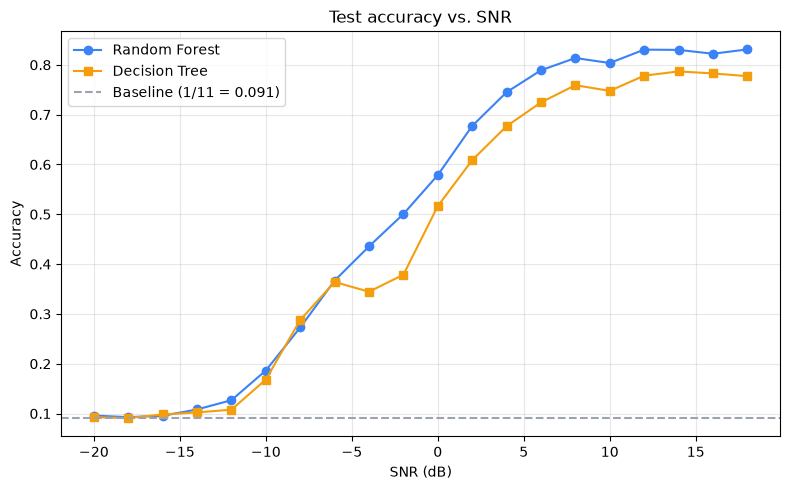

In [15]:
baseline = 1 / 11

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    list(accuracy_by_snr.keys()), list(accuracy_by_snr.values()),
    marker="o", color="#3B82F6", label="Random Forest",
)
ax.plot(
    list(dt_accuracy_by_snr.keys()), list(dt_accuracy_by_snr.values()),
    marker="s", color="#F59E0B", label="Decision Tree",
)
ax.axhline(baseline, linestyle="--", color="#9CA3AF", label=f"Baseline (1/11 = {baseline:.3f})")

ax.set_xlabel("SNR (dB)")
ax.set_ylabel("Accuracy")
ax.set_title("Test accuracy vs. SNR")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig("../figures/accuracy_vs_snr.png", dpi=150)
plt.show()


### Confusion matrices (Random Forest)

Row-normalized confusion matrices for the chosen model: one over the whole test set, one restricted to `snr >= 10` dB, so the second shows what the model actually confuses once noise isn't the dominant source of error. Saved to `figures/confusion_matrix_all_snr.png` and `figures/confusion_matrix_snr_ge10.png`.

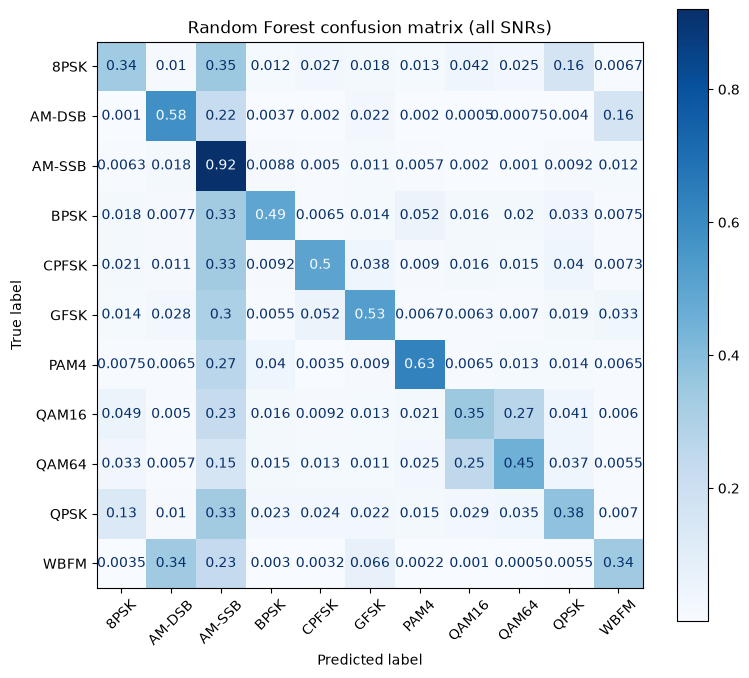

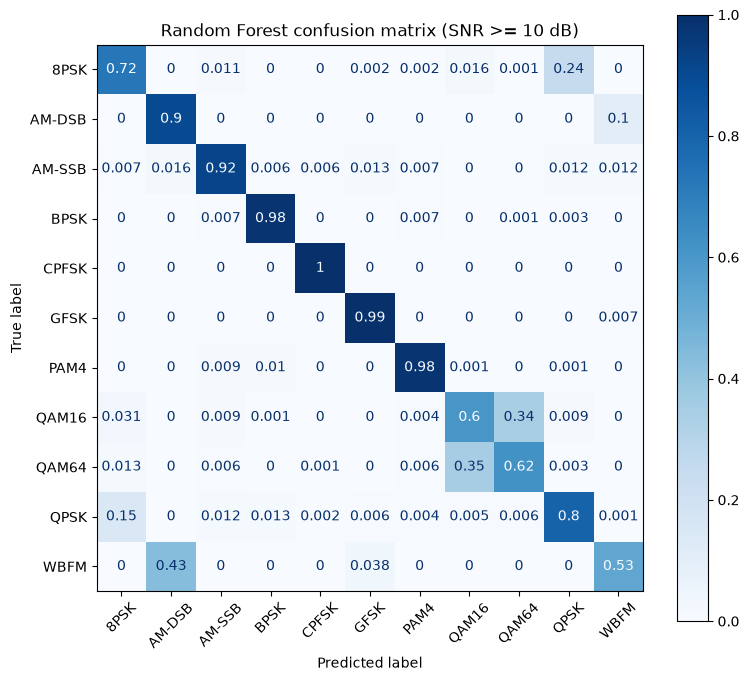

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

class_labels = model.classes_

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=class_labels,
    display_labels=class_labels,
    normalize="true",
    cmap="Blues",
    ax=ax,
    xticks_rotation=45,
)
ax.set_title("Random Forest confusion matrix (all SNRs)")
fig.tight_layout()
fig.savefig("../figures/confusion_matrix_all_snr.png", dpi=150)
plt.show()

high_snr_mask = snr_test >= 10
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test[high_snr_mask], y_pred[high_snr_mask],
    labels=class_labels,
    display_labels=class_labels,
    normalize="true",
    cmap="Blues",
    ax=ax,
    xticks_rotation=45,
)
ax.set_title("Random Forest confusion matrix (SNR >= 10 dB)")
fig.tight_layout()
fig.savefig("../figures/confusion_matrix_snr_ge10.png", dpi=150)
plt.show()


### Feature importances

Ranks the 12 hand-engineered features by how much they contributed to the Random Forest's splits. Saved to `figures/feature_importances.png`.

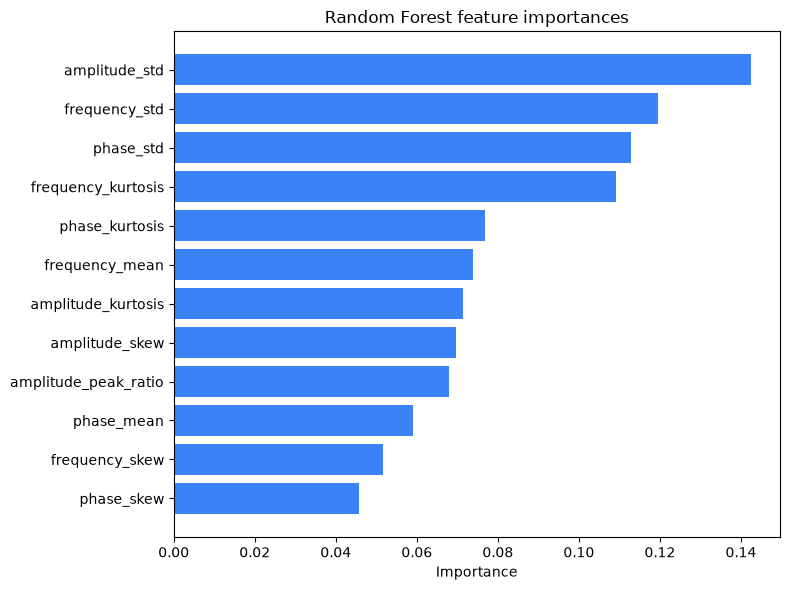

In [17]:
importances = pd.Series(
    model.named_steps["randomforestclassifier"].feature_importances_,
    index=X.columns,
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importances.index, importances.values, color="#3B82F6")
ax.set_xlabel("Importance")
ax.set_title("Random Forest feature importances")
fig.tight_layout()
fig.savefig("../figures/feature_importances.png", dpi=150)
plt.show()


## Discussion

The model performs relatively well for values up to -10dB, reaching 50% at around -2dB, before hitting a plateau between 80-83%. Once the SNR reaches around 6-8dB the model is really starting to show some usefulness. At higher SNR (>=10) the model really starts to struggle, classifying QAM16 and QAM64 incorrectly 34% and 27% of the time respectively; QPSK and 8PSK incorrectly 24% and 15% of the time; and WBFM and AM-DSB incorrectly 43% and 11% of the time. However, when looking at the classification matrix across all SNRs it looks like most classes have been classified incorrectly into AM-SSB. This is an artefact of the noise floor. QAM16/QAM64 were flagged as being likely to be confused, and this is accurate. They have the same constellation type (square) and the only difference is the density of points. This means that features like amplitude, phase std and skew won’t pick up the differences between these two signals. 8PSK and QPSK are confused due to the same reasoning. As they’re both Constant Envelope modulation types, they’ll have similar phase statistics. WBFM and AM-DSB are confused as both carry analogue signals so have similar amplitude and frequency statistics. This ties back to the findings from day 2, where we saw that modulation types could be identified based on the constellation shape. However this doesn’t take into account the more detailed statistics of modulation types within families. Looking at the feature importances, we see that amplitude_std, frequency_std and phase_std are the most important features. This implies that the model is mainly using the spread of envelope, phase and IF of each signal. This is good enough to identify the main modulation families (PSK/FSK/QAM/analogue) however is not detailed enough to determine the order/mechanism of the modulation type.